# ENG5338 Coursework 2 — GAS4
## Gas-turbine CO estimation

**Selected pipeline: Extra Trees.** Compare Linear Regression, Random Forest, Extra Trees and Histogram Gradient Boosting on shared chronological development folds. Predict contemporaneous CO (mg/m³) from nine ambient/process measurements.

Extra Trees achieves development-validation MAE **0.7226 mg/m³**, coverage **81.76%**, and median single-row latency **19.03 ms**. The project target is 90% coverage within ±1 mg/m³.

**Selection history:** HGB was assessed first under an initial 10 ms timing gate. After reviewing its result, Wenyi prioritised predictive MAE and selected Extra Trees using the existing development ranking. Both models were assessed on the same 2014–2015 observations; CW1 also used these years. Original HGB records are in `results/final/`, and Extra Trees records are in `results/final_extra_trees/`. Further confirmation uses a new future period.

Run the full repository with its data, `src/` and saved evidence. Default execution performs shared validation and checks the recorded searches, timing samples and assessments. Explicit switches enable grid and fixed-model replay.

Dataset: Kaya, Tüfekci and Uzun (2019), *Gas Turbine CO and NOx Emission Data Set*, UCI, DOI **10.24432/C5WC95**.

## 1. Runtime, data checks and common protocol

In [1]:
from pathlib import Path
import sys
# Support the project root, its experiments folder, or the parent VS Code workspace.
locations = [Path.cwd(), Path.cwd() / "ENG5338_CW2", Path.cwd().parent]
PROJECT = next((p for p in locations if (p / "src/cw2_project.py").is_file()), None)
assert PROJECT is not None, "Extract/download the whole repository and run from its root or experiments folder."
sys.path.insert(0, str(PROJECT / "src"))
from cw2_project import *
from IPython.display import display, Image
THREAD_CONTROLLER = threadpool_limits(limits=1)
np.random.seed(SEED)

RESULTS = PROJECT / "results/development"
FIGURES = PROJECT / "figures/development"
RESULTS.mkdir(parents=True, exist_ok=True)
RUNTIME = runtime_record()
write_json(RESULTS / "runtime.json", RUNTIME)
display(RUNTIME)
schema, integrity = data_check(RESULTS)
display(schema)
display(integrity)
X_dev, y_dev, FOLDS = load_development(PROJECT / "data/gas-turbine-emissions.csv")
write_json(RESULTS / "protocol.json", {**PROTOCOL, "protocol_id": PROTOCOL_ID})
fold_table = pd.DataFrame([{"fold":i+1,"train_rows":len(tr),"validation_rows":len(va),
    "last_training_row":int(tr[-1]),"first_validation_row":int(va[0]),"last_validation_row":int(va[-1])}
    for i,(tr,va) in enumerate(FOLDS)])
fold_table.to_csv(RESULTS / "folds.csv", index=False)
display(fold_table)


{'recorded_at_utc': '2026-11-13T02:46:18.770914+00:00',
 'python': '3.12.9 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:27) [GCC 11.2.0]',
 'executable': '<home>/Intro_to_AI_ML/ENG5338_CW1/.venv/bin/python',
 'platform': 'Linux-5.15.0-139-generic-x86_64-with-glibc2.31',
 'cpu': 'AMD Ryzen 7 5800H with Radeon Graphics',
 'logical_cpus': 16,
 'ram_gib': 15.467456817626953,
 'seed': 42,
 'numerical_threads': 1,
 'search_workers': 1,
 'accelerator': 'CPU only',
 'versions': {'numpy': '2.5.4',
  'pandas': '3.0.6',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'matplotlib': '3.11.2',
  'psutil': '7.2.2',
  'threadpoolctl': '3.7.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'thread_pools': [{'user_api': 'blas',
   'internal_api': 'openblas',
   'num_threads': 1,
   'prefix': 'libscipy_openblas',
   'filepath': '<home>/Intro_to_AI_ML/ENG5338_CW1/.venv/lib/python3.12/site-packages/scipy.libs/libscipy_openblas-5f890258.so',
   'version': '0.3.31.dev',
   'threading_layer'

,field,dtype,missing
0,year,int64,0
1,at,float64,0
2,ap,float64,0
3,ah,float64,0
4,afdp,float64,0
5,gtep,float64,0
6,tit,float64,0
7,tat,float64,0
8,tey,float64,0
9,cdp,float64,0


{'data_sha256': '6295ecd391e757ab5e029bdb54aee607887374861f656a26281b5a0e4e524b85',
 'shape': [36733, 12],
 'missing_values': 0,
 'duplicate_complete_rows': 7,
 'rows_by_year': {'2011': 7411,
  '2012': 7628,
  '2013': 7152,
  '2014': 7158,
  '2015': 7384},
 'prior_cw1_test_exposure': True,
 'cw2_final_test_run': True}

,fold,train_rows,validation_rows,last_training_row,first_validation_row,last_validation_row
0,1,3677,3698,3676,3701,7398
1,2,7375,3698,7374,7399,11096
2,3,11073,3698,11072,11097,14794
3,4,14771,3698,14770,14795,18492
4,5,18469,3698,18468,18493,22190


Development uses 2011–2013 (22,191 rows); later assessment uses 2014–2015 (14,542 rows). Five expanding folds validate 3,698 rows each, separated from fitting rows by a 24-row gap. Median imputation and OLS scaling fit the training observations of each fold.

The receipt protocol identifies the shared folds and metrics. The Extra Trees decision record describes the revised accuracy-first selection. The original 10 ms figure remains available as a timing reference.

## 2. Submitted tuning evidence and selected configurations

In [2]:
search_records = [check_search_evidence(name, FOLDS) for name in MODELS if name in SUBMITTED]
search_table = pd.DataFrame(search_records)
search_table.to_csv(RESULTS / "submitted_search_audit.csv", index=False)
display(search_table)
for name in MODELS:
    print(name, model_spec(name)[3])


,model,configurations,cv_fits,submitted_validation_mae,source,selected_params
0,random_forest,3,15,0.737145,results/submitted/member2/latest,"{'model__max_depth': 11, 'model__max_features'..."
1,extra_trees,27,135,0.722594,results/submitted/member3/latest,"{'model__max_depth': 14, 'model__max_features'..."
2,hist_gradient_boosting,8,40,0.765503,results/submitted/member4/latest,"{'model__l2_regularization': 1.0, 'model__lear..."


linear_reference {}
random_forest {'model__max_depth': 11, 'model__max_features': 0.5, 'model__max_samples': 0.9, 'model__min_samples_leaf': 20, 'model__n_estimators': 600}
extra_trees {'model__max_depth': 14, 'model__max_features': 0.8, 'model__min_samples_leaf': 10, 'model__n_estimators': 400}
hist_gradient_boosting {'model__l2_regularization': 1.0, 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 15}


The latest searches contain 3 RF configurations/15 CV fits, 27 Extra Trees configurations/135 fits and 8 HGB configurations/40 fits. OLS uses one fixed configuration. The earlier 24-configuration Extra Trees search is retained as history.

RF selects 600 trees, depth 11, leaf size 20, max_features=0.5 and max_samples=0.9. Extra Trees selects 400 trees, depth 14, leaf size 10 and max_features=0.8. HGB selects learning_rate=0.05, max_leaf_nodes=15 and L2=1, with 200 iterations and early_stopping=False. Depth, leaf size and L2 control model complexity.

The switch below replays the latest received grids. Search exports and replay results use separate directories.

In [3]:
RUN_FULL_SEARCHES = False  # Set True to reproduce all 38 latest submitted configurations (190 CV fits).
if RUN_FULL_SEARCHES:
    for name in MODELS:
        if name in SUBMITTED:
            rerun_submitted_search(name, PROJECT / "results/search_reruns" / name)
else:
    print("Checking saved member searches and common-environment replays.")
    for name in SUBMITTED:
        replay = PROJECT / "results/search_reproduction" / name
        results = pd.read_csv(replay / "search_results.csv")
        supplied = pd.read_csv(PROJECT / "results/submitted" / SUBMITTED[name] / "search_results.csv")
        import ast
        assert ast.literal_eval(results.loc[results.mean_test_mae.idxmax(), "params"]) == model_spec(name)[3]
        assert len(results) == len(supplied)
    display(pd.read_csv(PROJECT / "results/search_reproduction/comparison.csv"))

Checking saved member searches and common-environment replays.


,model,configurations,cv_fits,replayed_validation_mae,submitted_validation_mae,difference
0,random_forest,3,15,0.737212,0.737145,0.000067
1,extra_trees,27,135,0.722594,0.722594,0.000000
2,hist_gradient_boosting,8,40,0.765503,0.765503,0.000000


## 3. Common five-fold validation

In [4]:
SUMMARIES, DETAILS, PREDICTIONS = [], {}, {}
for name in MODELS:
    summary, detail, oof = evaluate_selected(name, RESULTS / name)
    summary["runtime_id"] = RUNTIME["runtime_id"]
    write_json(RESULTS / name / "summary.json", summary)
    SUMMARIES.append(summary)
    DETAILS[name], PREDICTIONS[name] = detail, oof
comparison = pd.DataFrame(SUMMARIES).drop(columns=["best_params"])
comparison.to_csv(RESULTS / "comparison.csv", index=False)
display(comparison[["model","train_mae","validation_mae","validation_mae_sd","validation_rmse",
                    "validation_r2","validation_coverage","worst_fold_coverage","mae_gap"]])
# Verify preprocessing uses training observations only.
tr, va = FOLDS[0]
audit = clone(pipeline_for("linear_reference")).fit(X_dev.iloc[tr], y_dev.iloc[tr])
np.testing.assert_allclose(audit.named_steps["impute"].statistics_, X_dev.iloc[tr].median())
np.testing.assert_allclose(audit.named_steps["scale"].mean_, X_dev.iloc[tr].mean())
print("Fold-local preprocessing audit passed.")


linear_reference: completed development fold 1/5


linear_reference: completed development fold 2/5


linear_reference: completed development fold 3/5


linear_reference: completed development fold 4/5


linear_reference: completed development fold 5/5


random_forest: completed development fold 1/5


... (12 outputs left out)

hist_gradient_boosting: completed development fold 4/5


hist_gradient_boosting: completed development fold 5/5


,model,train_mae,validation_mae,validation_mae_sd,validation_rmse,validation_r2,validation_coverage,worst_fold_coverage,mae_gap
0,linear_reference,0.673202,0.907319,0.151111,1.689245,0.480491,0.718010,0.573824,0.234117
1,random_forest,0.413976,0.737212,0.085729,1.507902,0.576657,0.811790,0.691996,0.323236
2,extra_trees,0.409309,0.722594,0.086560,1.473532,0.595456,0.817631,0.714170,0.313285
3,hist_gradient_boosting,0.411146,0.765503,0.106708,1.465743,0.597406,0.791509,0.669551,0.354357


Fold-local preprocessing audit passed.


Each row averages five equal-size validation blocks. MAE standard deviation describes variation across the periods. The same folds support parameter selection and model comparison. The shared-runtime results provide the report's comparison values; source-owner scores remain recorded alongside their environments.

## 4. Training gaps, temporal performance and high-CO errors

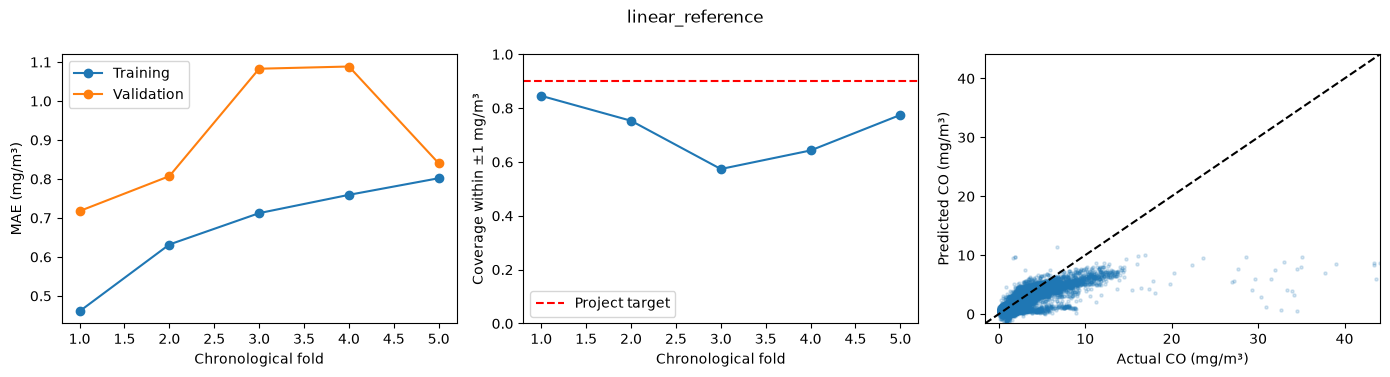

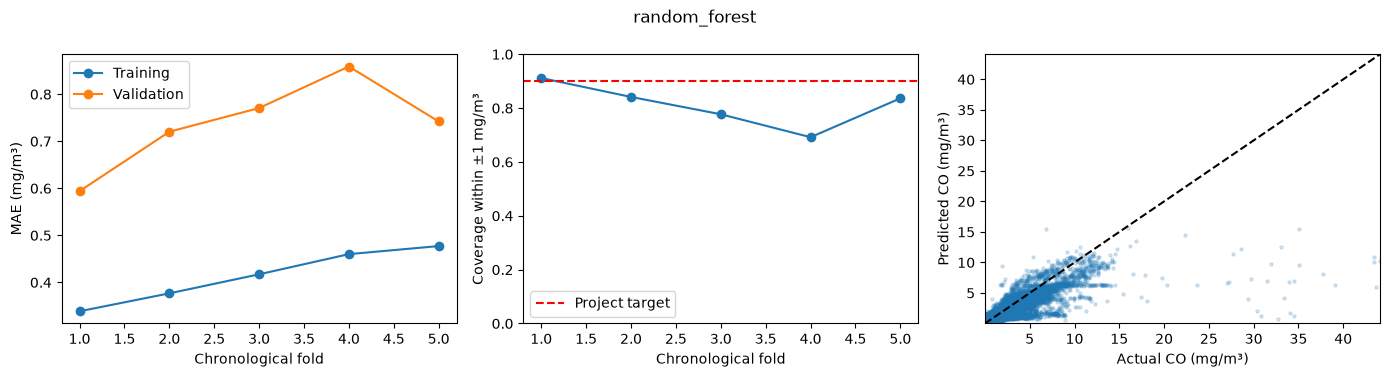

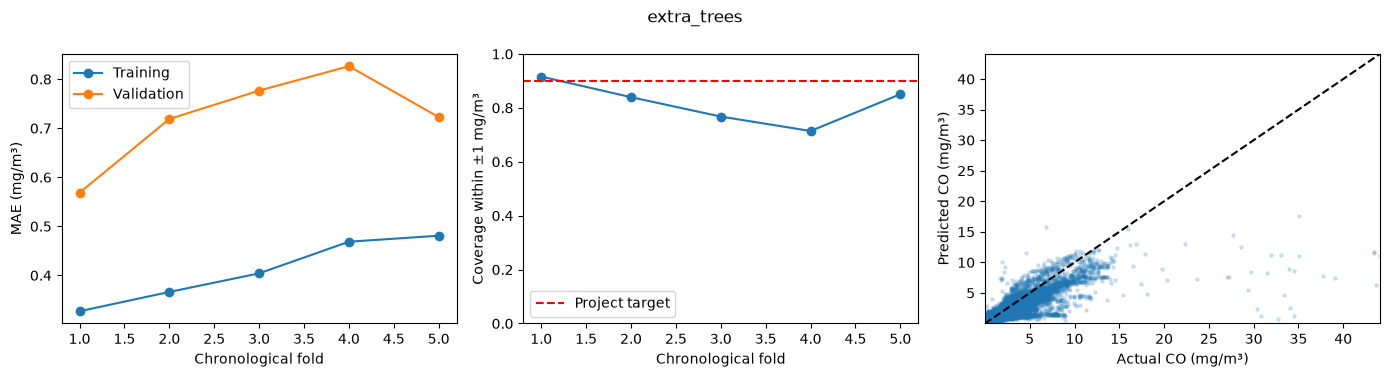

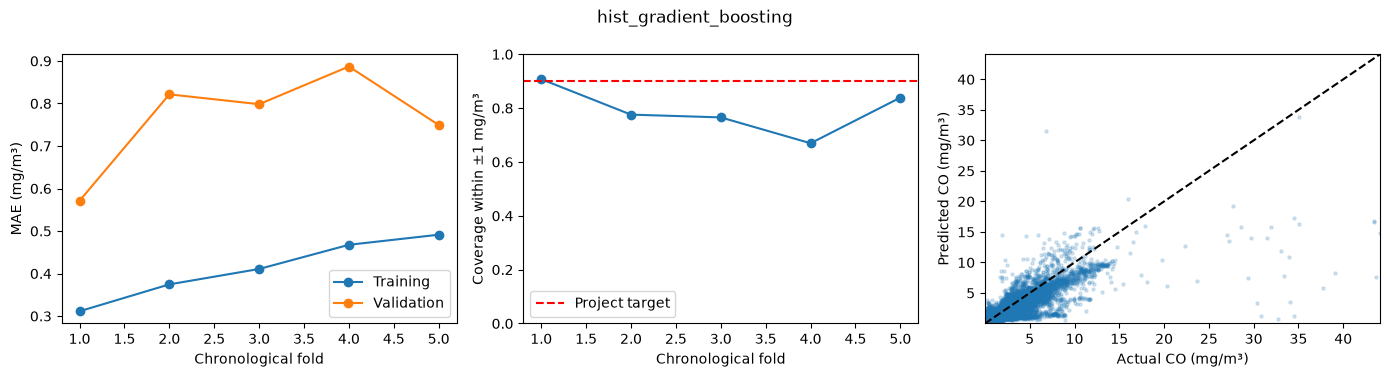

,model,group,rows,mae,coverage,mean_prediction_minus_actual
0,linear_reference,all_validation,18490,0.907319,0.718010,-0.601841
1,linear_reference,above_training_q75,7267,1.474214,0.491124,-1.121917
2,linear_reference,above_training_q95,2211,2.623523,0.260063,-2.596492
3,random_forest,all_validation,18490,0.737212,0.811790,-0.366580
4,random_forest,above_training_q75,7267,1.254633,0.586624,-0.967799
5,random_forest,above_training_q95,2211,2.289344,0.275893,-1.987201
6,extra_trees,all_validation,18490,0.722594,0.817631,-0.368496
7,extra_trees,above_training_q75,7267,1.245883,0.589927,-0.973863
8,extra_trees,above_training_q95,2211,2.267245,0.266848,-1.967220
9,hist_gradient_boosting,all_validation,18490,0.765503,0.791509,-0.343029


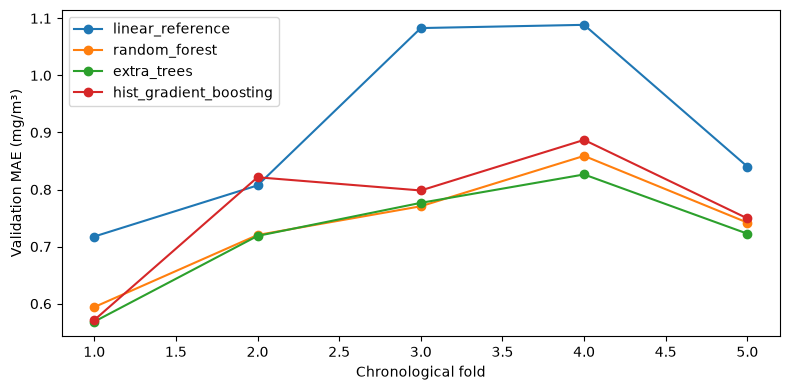

In [5]:
tail_tables=[]
for name in MODELS:
    fig = make_diagnostics(name, DETAILS[name], PREDICTIONS[name], FIGURES)
    display(fig)
    plt.close(fig)
    table=high_co_diagnostics(PREDICTIONS[name]);table.insert(0,"model",name)
    table.to_csv(RESULTS / name / "high_co_diagnostics.csv",index=False)
    tail_tables.append(table)
tail_comparison=pd.concat(tail_tables,ignore_index=True)
tail_comparison.to_csv(RESULTS / "high_co_comparison.csv",index=False)
display(tail_comparison)
fig, ax=plt.subplots(figsize=(8,4))
for name in MODELS:
    ax.plot(DETAILS[name].fold, DETAILS[name].validation_mae,"o-",label=name)
ax.set(xlabel="Chronological fold",ylabel="Validation MAE (mg/m³)")
ax.legend();fig.tight_layout();fig.savefig(FIGURES / "model_comparison.png",dpi=160)
plt.show()


All nonlinear candidates improve validation MAE and coverage over OLS. Extra Trees has the lowest MAE and highest coverage. HGB has the lowest mean fold RMSE and highest mean fold R². MAE is the primary selection objective.

Training–validation gaps and changes across folds identify the generalisation challenge. High-CO thresholds use training-fold quantiles; measured validation CO defines the diagnostic groups. The saved residuals show larger errors and systematic underprediction at high concentrations.

## 5. Model-owner interpretation and actual contributions

**Member 1 — Wenyi Liu:** coordinated the shared framework, baseline, validation protocol and integration, with Codex/ChatGPT assistance.

**Member 2 — Jiaqi Chen (Kiki):** supplied RF tuning results, scatter plots and model interpretation. Used ChatGPT for coding and writing assistance.

**Member 3 — Sirawich Anantapong (Poon):** supplied successive Extra Trees experiments, the selected configuration, plots and analysis. Used Claude for explanation, plotting and wording assistance.

**Member 4 — Hansini Devaraja:** supplied HGB tuning, fold metrics, figures and analysis. Used ChatGPT for learning and troubleshooting.

**Member 5 — Sauhandikaa Senthil Arumugam:** supplied independent Windows cost measurements, environment records and accuracy–cost analysis. Used ChatGPT for setup, verification and writing assistance.

Codex assisted integration, both assessment runs, document drafting and checks under Wenyi's instruction. Detailed received analyses are in `notes/`.

## 6. Computational cost — Member 5 entry

Member 5 measured all four full pipelines on the same Windows laptop: Python 3.10.6, scikit-learn 1.7.2, 22,191 development rows and one numerical thread. The method uses three timed fits, 100 single-row timings and ten 1,000-row batch timings after warm-up. RSS is sampled approximately every 5 ms; serialized size is saved separately.

Validation runs use Linux with Python 3.12.9 and scikit-learn 1.9.1. Current reported costs are in `results/member5_local_py310/`; earlier Linux measurements are in `results/costs/`.

In [6]:
from cw2_submission import (verify_member5, comparison_table, decision_lock,
    evaluate_final_once, replay_fixed_final, submission_figures, LABELS)
cost_table, member5_runtime = verify_member5()
display(cost_table[["model","fit_median_s","single_median_ms","single_p95_ms",
    "batch_1000_median_ms","fit_sampled_rss_increment_mib","serialized_pipeline_kib"]])
display(member5_runtime)
print("Verified Member 5 timing medians, p95 and environment.")

,model,fit_median_s,single_median_ms,single_p95_ms,batch_1000_median_ms,fit_sampled_rss_increment_mib,serialized_pipeline_kib
0,linear_reference,0.020540,0.69520,0.961125,0.82425,0.023438,1.595703
1,random_forest,24.492939,27.18060,34.910190,69.83375,25.539062,24068.304688
2,extra_trees,5.218665,19.02550,22.604065,56.08000,45.320312,44718.178711
3,hist_gradient_boosting,0.554191,2.86365,4.541640,19.11550,6.128906,364.974609


{'recorded_at_utc': '2026-11-12T01:25:03.037095+00:00',
 'python': '3.10.6 (tags/v3.10.6:9c7b4bd, Aug  1 2022, 21:53:49) [MSC v.1932 64 bit (AMD64)]',
 'executable': 'e:\\AI\\ENG5338_CW2\\.venv\\Scripts\\python.exe',
 'platform': 'Windows-10-10.0.22631-SP0',
 'cpu': 'Intel64 Family 6 Model 140 Stepping 1, GenuineIntel',
 'logical_cpus': 8,
 'ram_gib': 7.64794921875,
 'seed': 42,
 'numerical_threads': 1,
 'search_workers': 1,
 'accelerator': 'CPU only',
 'versions': {'numpy': '2.2.6',
  'pandas': '2.3.3',
  'scipy': '1.15.3',
  'scikit-learn': '1.7.2',
  'matplotlib': '3.10.0',
  'psutil': '7.2.2',
  'threadpoolctl': '3.8.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'thread_pools': [{'user_api': 'openmp',
   'internal_api': 'openmp',
   'num_threads': 1,
   'prefix': 'vcomp',
   'filepath': 'E:\\AI\\ENG5338_CW2\\.venv\\Lib\\site-packages\\sklearn\\.libs\\vcomp140.dll',
   'version': None},
  {'user_api': 'blas',
   'internal_api': 'openblas',
   'num_threads': 1,
   'prefix': '

Verified Member 5 timing medians, p95 and environment.


## 7. Model selection and target comparison

In [7]:
combined = comparison_table()
(PROJECT / "results/submission").mkdir(parents=True, exist_ok=True)
combined.to_csv(PROJECT / "results/submission/comparison.csv", index=False)
display(combined[["model","train_mae","validation_mae","validation_rmse","validation_r2",
    "coverage_percent","mae_gap","fit_median_s","single_median_ms","coverage_pass","latency_pass","both_pass"]])
assert combined.sort_values("validation_mae").iloc[0].model == "extra_trees"
assert not combined.coverage_pass.any()
print("Selected Extra Trees by development MAE. Timing columns retain the original 10 ms reference; coverage columns compare the 90% target.")

,model,train_mae,validation_mae,validation_rmse,validation_r2,coverage_percent,mae_gap,fit_median_s,single_median_ms,coverage_pass,latency_pass,both_pass
0,linear_reference,0.673202,0.907319,1.689245,0.480491,71.800973,0.234117,0.020540,0.69520,False,True,False
1,random_forest,0.413976,0.737212,1.507902,0.576657,81.179016,0.323236,24.492939,27.18060,False,False,False
2,extra_trees,0.409309,0.722594,1.473532,0.595456,81.763115,0.313285,5.218665,19.02550,False,False,False
3,hist_gradient_boosting,0.411146,0.765503,1.465743,0.597406,79.150892,0.354357,0.554191,2.86365,False,True,False


Selected Extra Trees by development MAE. Timing columns retain the original 10 ms reference; coverage columns compare the 90% target.


Extra Trees is selected by the lowest development-validation MAE (0.7226 mg/m³) and highest coverage (81.76%). Single-row latency is 19.03 ms. The accuracy-first choice followed the initial HGB assessment and used the existing development ranking.

Selected settings: median imputation → 400 trees, max_depth=14, min_samples_leaf=10, max_features=0.8, bootstrap=False, random_state=42 and n_jobs=1. The coverage target remains 90%.

## 8. Extra Trees assessment and experiment history

HGB was assessed first: MAE 0.8998 mg/m³ and coverage 70.00%. The later accuracy-first decision selected Extra Trees using development scores, saved its configuration and assessed it on the same 2014–2015 observations. Both records are retained. These years were also used in CW1.

The following cell loads or computes the selected Extra Trees assessment, checks its saved metrics and shows the HGB history. A replay switch reproduces the fixed Extra Trees predictions. New future observations provide the next confirmation stage.

Verified saved assessment metrics and loaded predictions.


{'assessment_history': [{'model': 'hist_gradient_boosting',
   'mae': 0.899841513050367,
   'rmse': 1.534895235972777,
   'r2': 0.5085005363747006,
   'coverage': 0.7000412597992023,
   'negative_fraction': 0.0},
  {'model': 'extra_trees',
   'mae': 0.8011292039095628,
   'rmse': 1.365361134019513,
   'r2': 0.6110796711019568,
   'coverage': 0.7335992298170816,
   'negative_fraction': 0.0}]}

{'model': 'extra_trees',
 'locked_at_utc': '2026-11-13T02:29:56.798784+00:00',
 'selection_metric': 'existing development-validation MAE'}

,partition,mae,rmse,r2,coverage,negative_fraction
0,full development fit,0.515897,1.088976,0.774987,0.901447,0.0
1,2014–2015 final assessment,0.801129,1.365361,0.611080,0.733599,0.0


,year,rows,mae,rmse,r2,coverage,negative_fraction
0,2014,7158,0.766645,1.335590,0.557066,0.767952,0.0
1,2015,7384,0.834558,1.393614,0.611131,0.700298,0.0


{'training_q95': 6.1675,
 'tail_rows': 701,
 'tail_test': {'mae': 2.0094285287961493,
  'rmse': 4.134598284167703,
  'r2': 0.15012089448251975,
  'coverage': 0.47218259629101283,
  'negative_fraction': 0.0},
 'negative_predictions': 0}

Loaded and verified saved assessment predictions.


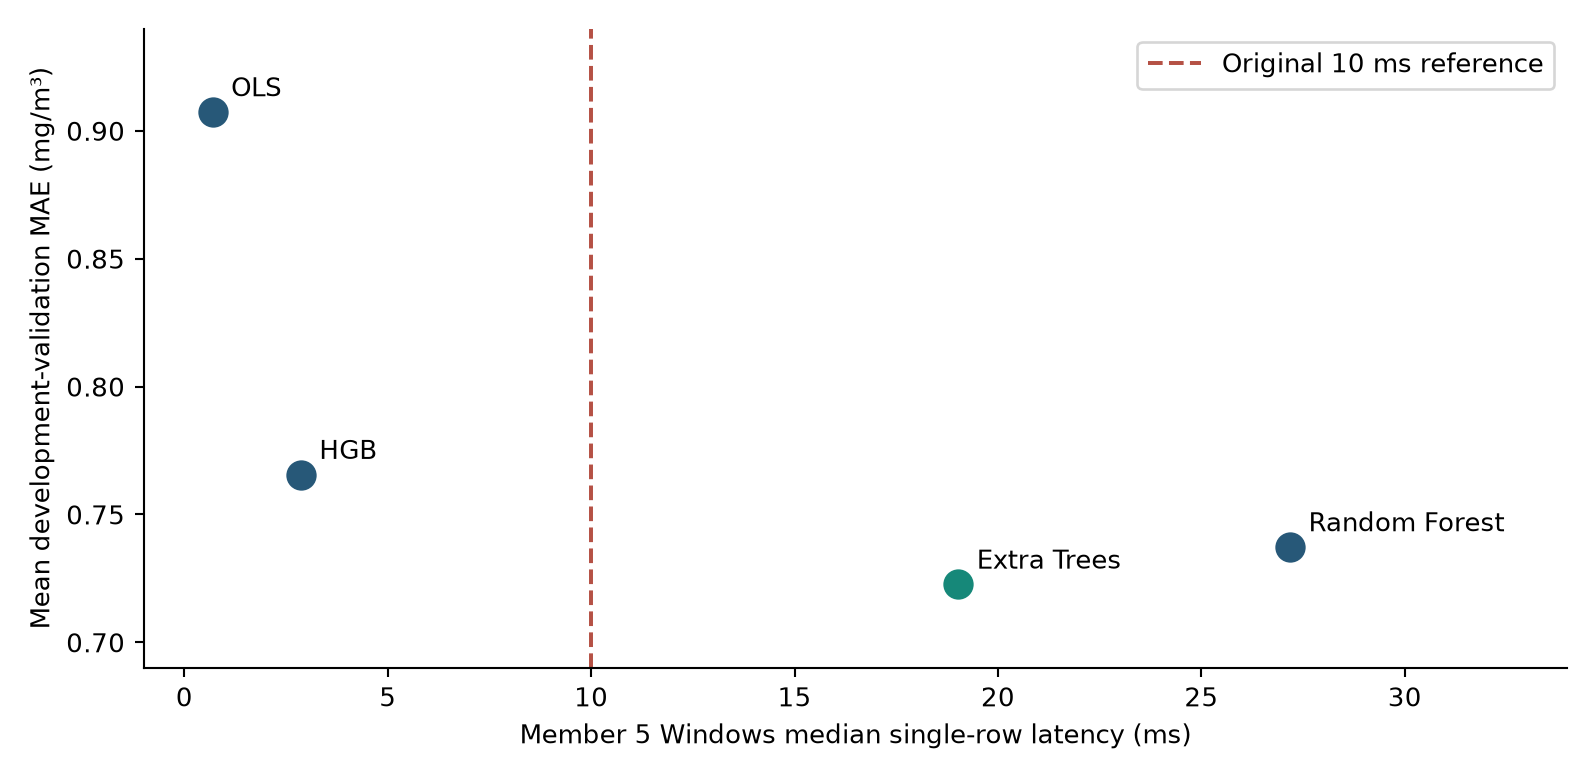

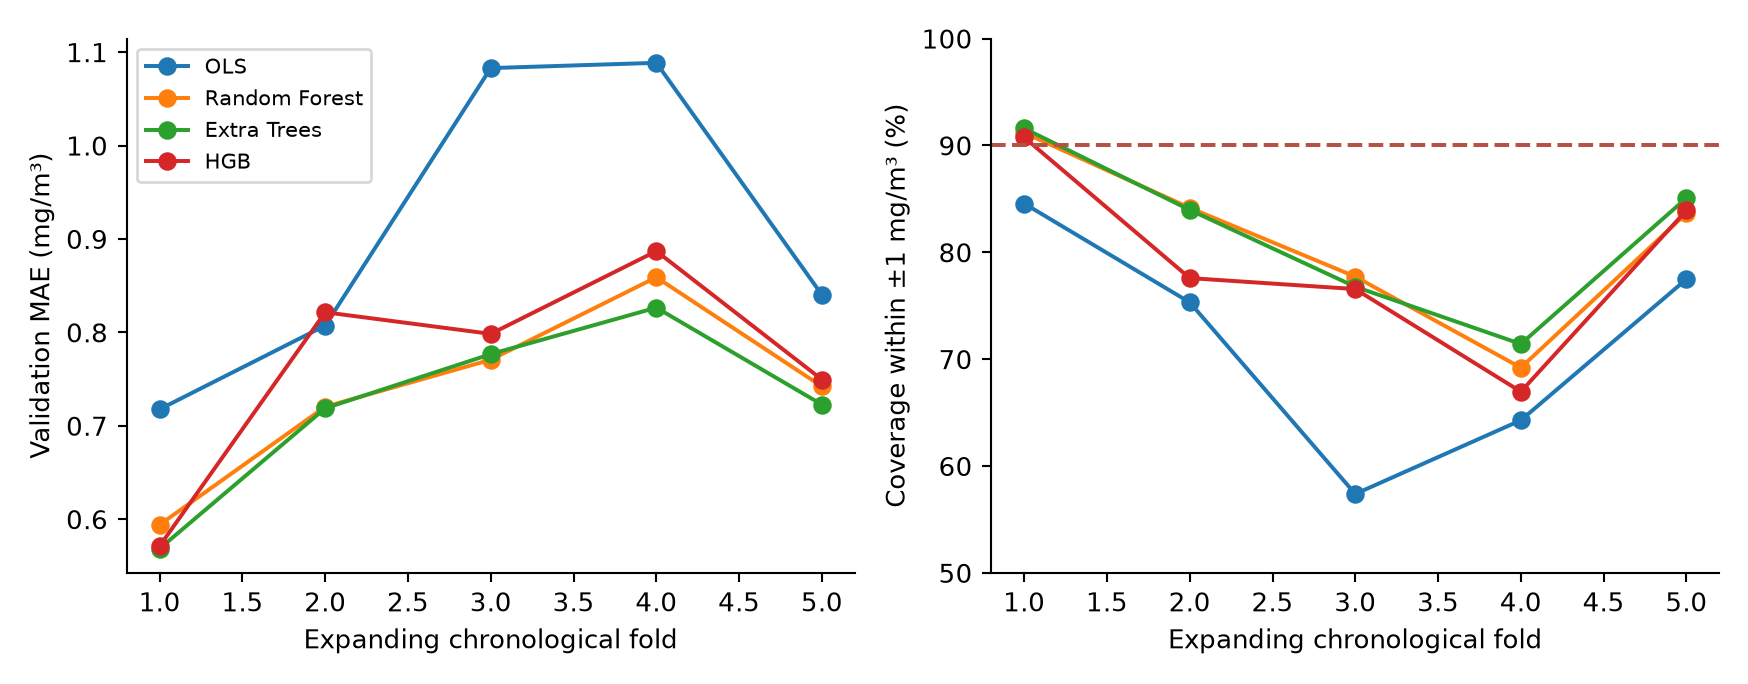

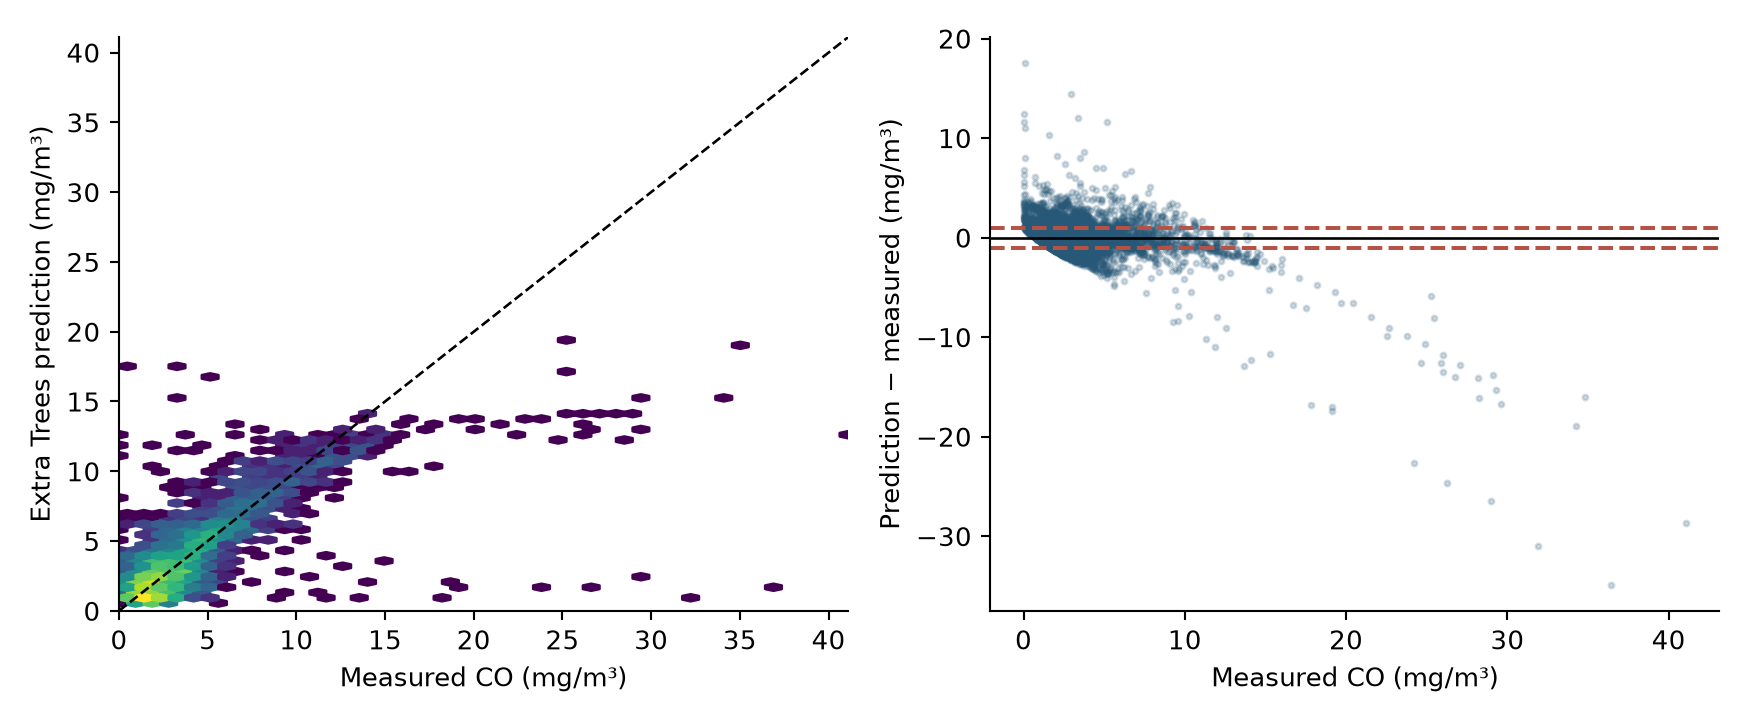

In [2]:
from IPython.display import Image
from cw2_submission import FINAL_DIR, PRIOR_FINAL_DIR, verify_final
lock = decision_lock()
final_result, final_predictions = evaluate_final_once()
prior_lock = json.loads((PRIOR_FINAL_DIR / "decision_lock.json").read_text())
prior_result, _ = verify_final(prior_lock)
display({"assessment_history": [{"model":"hist_gradient_boosting", **prior_result["test"]}, {"model":"extra_trees", **final_result["test"]}]})
display({k: lock[k] for k in ["model","locked_at_utc","selection_metric"]})
display(pd.DataFrame([{"partition":"full development fit", **final_result["training"]},
                      {"partition":"2014–2015 final assessment", **final_result["test"]}]))
display(pd.DataFrame(final_result["by_year"]))
display({"training_q95":final_result["training_q95"],"tail_rows":final_result["tail_rows"],
    "tail_test":final_result["tail_test"],"negative_predictions":final_result["negative_predictions"]})
REPLAY_FIXED_FINAL = False
if REPLAY_FIXED_FINAL:
    replay_fixed_final()
else:
    print("Loaded and verified saved assessment predictions.")
checks = json.loads((RESULTS / "data_checks.json").read_text())
checks["cw2_final_test_run"] = True
write_json(RESULTS / "data_checks.json", checks)
fig_dir = submission_figures(combined, final_predictions)
for filename in ["accuracy_cost.png","temporal_validation.png","final_diagnostics.png"]:
    display(Image(filename=str(fig_dir / filename)))
write_json(PROJECT / "results/submission/evidence.json", {
    "comparison":combined.to_dict("records"), "final":final_result,
    "member5_runtime":member5_runtime, "development_runtime":RUNTIME,
    "data_checks":json.loads((RESULTS / "data_checks.json").read_text()),
    "decision":lock, "prior_hgb":prior_result, "protocol":{**PROTOCOL,"protocol_id":PROTOCOL_ID}})

## 9. Conclusions and contributions

**Conclusion:** Extra Trees is the preferred accuracy-first model. Development coverage is 81.76% against the 90% target. The assessment shows the remaining coverage gap and high-CO error concentration. Next work will collect representative high-CO data, test additional features, measure operational robustness and evaluate a new future period.

**Recorded workflow:** HGB was evaluated first, the priority changed to development MAE, and Extra Trees was assessed on the same later-year data. Both experiment records and configuration hashes are retained.

**Contributions and AI:** members supplied their assigned model experiments and Windows computational comparison. Wenyi coordinated the shared framework and integration. Codex assisted coding, assessment, analysis, report/slides drafting and checks. Member-specific AI use appears in Section 5 and the contribution statement. Review status: awaiting all members' confirmation. Member 5's student ID is blank pending receipt.

References: Kaya et al. (2019), UCI DOI 10.24432/C5WC95; supplied CW2 brief/template; scikit-learn ensemble and TimeSeriesSplit documentation.